# Week 9 — Naive result (Project 1)

Every choice comes from lock note v2 (reports/lock_note_v2.pdf). Runs from the cache, no network.
Full run: `python -m src.week9` (the long part, 1–3 h). This notebook reruns it only if
`reports/week9_results.json` is missing, then shows the saved numbers and figures.

In [1]:
import os, sys, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import pandas as pd
from IPython.display import Image, display
from src import week9
if not Path("reports/week9_results.json").exists():
    week9.main()
R = json.loads(Path("reports/week9_results.json").read_text())
print("seeds", R["seeds"], "| folds", R["folds"], "| config", R["config_version"], "| runtime (min)", R["runtime_min"])

seeds [0, 1, 2] | folds 5 | config 0.2.0 | runtime (min) 85.4


## Overall scores (partition = all; mean ± SD over splits)

In [2]:
rows = []
for wt, d in R["overall"].items():
    for metric, dd in d.items():
        for key, (mu, sd) in dd.items():
            tau, model, st = key.split("|")
            rows.append(dict(weighting=wt, metric=metric, tau=int(tau), model=model, set=st, mean=mu, sd=sd))
T = pd.DataFrame(rows)
for wt in ("type", "neuron"):
    print(wt + "-weighted, tau = 10")
    display(T[(T.tau == 10) & (T.weighting == wt) & T.set.isin(["within", "cross", "unmatched", "efferent"])]
            .pivot_table(index=["model", "set"], columns="metric", values="mean").round(3))

type-weighted, tau = 10


metric                     accuracy  balanced_accuracy  cost_flow1210  \
model           set                                                     
logreg          cross         0.903              0.604          0.177   
                efferent      0.000                NaN          6.419   
                unmatched     0.850              0.492          0.227   
                within        0.843              0.601          0.259   
logreg_balanced cross         0.789              0.696          0.416   
                efferent      0.000                NaN          5.940   
                unmatched     0.760              0.602          0.493   
                within        0.764              0.745          0.496   
majority        cross         0.030              0.110          1.107   
                efferent      0.000                NaN          2.000   
                unmatched     0.044              0.100          1.159   
                within        0.084              0.100          1.113   
rf              cross         0.903              0.569          0.180   
                efferent      0.000                NaN          6.148   
                unmatched     0.865              0.463          0.219   
                within        0.854              0.563          0.245   

metric                     cost_flow125  cost_unit  macro_f1  
model           set                                           
logreg          cross             0.168      0.097     0.634  
                efferent          3.657      1.000       NaN  
                unmatched         0.220      0.150     0.499  
                within            0.244      0.157     0.606  
logreg_balanced cross             0.380      0.211     0.552  
                efferent          3.310      1.000       NaN  
                unmatched         0.416      0.240     0.422  
                within            0.431      0.236     0.554  
majority        cross             1.107      0.970     0.006  
                efferent          2.000      1.000       NaN  
                unmatched         1.159      0.956     0.008  
                within            1.113      0.916     0.016  
rf              cross             0.173      0.097     0.623  
                efferent          3.517      1.000       NaN  
                unmatched         0.212      0.135     0.488  
                within            0.231      0.146     0.590

neuron-weighted, tau = 10


metric                     accuracy  balanced_accuracy  cost_flow1210  \
model           set                                                     
logreg          cross         0.920              0.583          0.139   
                efferent      0.000                NaN          5.633   
                unmatched     0.850              0.609          0.189   
                within        0.908              0.601          0.155   
logreg_balanced cross         0.831              0.715          0.255   
                efferent      0.000                NaN          5.246   
                unmatched     0.787              0.684          0.406   
                within        0.833              0.750          0.306   
majority        cross         0.648              0.110          0.437   
                efferent      0.000                NaN          2.000   
                unmatched     0.036              0.100          1.169   
                within        0.557              0.100          0.592   
rf              cross         0.915              0.544          0.145   
                efferent      0.000                NaN          5.292   
                unmatched     0.864              0.577          0.182   
                within        0.908              0.560          0.159   

metric                     cost_flow125  cost_unit  macro_f1  
model           set                                           
logreg          cross             0.137      0.080     0.635  
                efferent          3.362      1.000       NaN  
                unmatched         0.185      0.150     0.590  
                within            0.149      0.092     0.639  
logreg_balanced cross             0.246      0.169     0.524  
                efferent          3.017      1.000       NaN  
                unmatched         0.342      0.213     0.514  
                within            0.260      0.167     0.508  
majority        cross             0.437      0.352     0.086  
                efferent          2.000      1.000       NaN  
                unmatched         1.169      0.964     0.007  
                within            0.592      0.443     0.071  
rf              cross             0.143      0.085     0.615  
                efferent          3.167      1.000       NaN  
                unmatched         0.179      0.136     0.574  
                within            0.154      0.092     0.617

## Cross-sex drop and within-animal floor by region and by dimorphism (type-weighted cost)

In [3]:
for part in ("drops_region4", "drops_dim"):
    display(pd.DataFrame({k: {c: f"{v[0]:+.3f} ± {v[1]:.3f}" for c, v in d.items()} for k, d in R[part].items()}).T)
print("bootstrap over cell types (logreg, seed 0):", json.dumps(R["bootstrap_drop_logreg_seed0"], indent=1))

,drop_cross,floor,drop_cross_shared,drop_cross_em
logreg|all,-0.076 ± 0.015,+0.006 ± 0.005,-0.022 ± 0.011,-0.060 ± 0.018
logreg|higher_order,-0.033 ± 0.008,+0.002 ± 0.002,-0.019 ± 0.007,-0.031 ± 0.009
logreg|motor_periphery,-0.087 ± 0.027,+0.002 ± 0.009,-0.013 ± 0.030,-0.061 ± 0.032
logreg|optic_lobe,-0.083 ± 0.052,+0.017 ± 0.024,+0.034 ± 0.042,-0.071 ± 0.059
logreg|sensory_periphery,-0.105 ± 0.061,+0.006 ± 0.024,-0.100 ± 0.057,+0.018 ± 0.118
logreg_balanced|all,-0.052 ± 0.021,+0.010 ± 0.007,-0.011 ± 0.019,+0.300 ± 0.100
logreg_balanced|higher_order,-0.032 ± 0.008,-0.002 ± 0.003,-0.008 ± 0.007,+0.328 ± 0.129
logreg_balanced|motor_periphery,+0.092 ± 0.027,+0.030 ± 0.028,+0.029 ± 0.036,+0.399 ± 0.094
logreg_balanced|optic_lobe,-0.142 ± 0.071,+0.018 ± 0.026,+0.064 ± 0.038,+0.262 ± 0.082
logreg_balanced|sensory_periphery,-0.008 ± 0.120,-0.007 ± 0.077,-0.073 ± 0.108,+0.405 ± 0.092


,drop_cross,floor,drop_cross_shared,drop_cross_em
logreg|all,-0.076 ± 0.015,+0.006 ± 0.005,-0.022 ± 0.011,-0.060 ± 0.018
logreg|dimorphic,-0.034 ± 0.143,+0.011 ± 0.035,-0.093 ± 0.186,-0.019 ± 0.142
logreg|isomorphic,-0.078 ± 0.015,+0.006 ± 0.005,-0.022 ± 0.011,-0.061 ± 0.018
logreg|sex_specific,+nan ± nan,+0.008 ± 0.041,+nan ± nan,+nan ± nan
logreg_balanced|all,-0.052 ± 0.021,+0.010 ± 0.007,-0.011 ± 0.019,+0.300 ± 0.100
logreg_balanced|dimorphic,-0.188 ± 0.137,+0.014 ± 0.101,-0.249 ± 0.175,+0.108 ± 0.280
logreg_balanced|isomorphic,-0.051 ± 0.021,+0.010 ± 0.007,-0.008 ± 0.018,+0.303 ± 0.100
logreg_balanced|sex_specific,+nan ± nan,-0.018 ± 0.092,+nan ± nan,+nan ± nan
majority|all,-0.005 ± 0.010,+nan ± nan,-0.008 ± 0.006,+nan ± nan
majority|dimorphic,+0.049 ± 0.074,+nan ± nan,+0.000 ± 0.031,+nan ± nan


bootstrap over cell types (logreg, seed 0): {
 "all": {
  "drop": -0.07449726433075554,
  "ci95": [
   -0.08455832605868092,
   -0.06429707676229637
  ]
 },
 "optic_lobe": {
  "drop": -0.08532155676297834,
  "ci95": [
   -0.13745203668613007,
   -0.02746016764285867
  ]
 },
 "sensory_periphery": {
  "drop": -0.10933065164318051,
  "ci95": [
   -0.16442702164066167,
   -0.05434247195309572
  ]
 },
 "motor_periphery": {
  "drop": -0.08077330178677739,
  "ci95": [
   -0.1140342192030112,
   -0.04879983195419924
  ]
 },
 "higher_order": {
  "drop": -0.031866278645566036,
  "ci95": [
   -0.03940531574836859,
   -0.024289247870546215
  ]
 }
}


## Unmatched MaleCNS neurons, efferent neurons, prior shift

In [4]:
display(pd.DataFrame(R["unmatched_vs_ref"]).T)
print("efferent -> predicted class (logreg, 5 fold models of seed 0):", R["efferent_predictions_logreg"])
print("EM priors, first split:", R["em_priors_logreg_first_split"])
print(json.dumps(R["eda_counts"], indent=1))
print("hyperparameters chosen:", R["hparams_counts"])

,cost,cost_sd,reference_within,n,coverage
logreg|neuron,0.1868,0.0310,0.2302,7149.0,0.988
logreg|type,0.2191,0.0306,0.2189,7149.0,0.988
logreg_balanced|neuron,0.3302,0.0294,0.3737,7149.0,0.988
logreg_balanced|type,0.4058,0.0231,0.4544,7149.0,0.988
majority|neuron,1.1615,0.0075,1.1615,7149.0,0.988
majority|type,1.1543,0.0060,1.1543,7149.0,0.988
rf|neuron,0.1792,0.0236,0.2164,7149.0,0.988
rf|type,0.2089,0.0185,0.2001,7149.0,0.988


efferent -> predicted class (logreg, 5 fold models of seed 0): {'optic': 34, 'sensory': 26, 'central': 10, 'ascending': 10}
EM priors, first split: {'seed': 0, 'fold': 0, 'em_prior': [0.0481, 0.0, 0.0132, 0.5852, 0.097, 0.0073, 0.2339, 0.0149, 0.0003, 0.0001], 'train_prior': [0.0698, 0.0042, 0.0131, 0.5958, 0.0619, 0.0031, 0.2414, 0.0095, 0.0008, 0.0004]}
{
 "fafb": {
  "neurons": 139255,
  "sensory": 16904,
  "R1-6": 8452,
  "region_LA": 9486,
  "super_class_share": {
   "optic": 0.5568,
   "central": 0.2325,
   "sensory": 0.1214,
   "visual_projection": 0.0577,
   "ascending": 0.0126,
   "descending": 0.0094,
   "sensory_ascending": 0.0044,
   "visual_centrifugal": 0.0038,
   "motor": 0.0008,
   "endocrine": 0.0006,
   "unknown": 0.0001
  }
 },
 "malecns": {
  "neurons": 144414,
  "sensory": 8918,
  "R1-6": 0,
  "region_LA": 1742,
  "super_class_share": {
   "optic": 0.619,
   "central": 0.2227,
   "visual_projection": 0.0637,
   "sensory": 0.0618,
   "ascending": 0.0127,
   "descend

## Figures (figures/week9/)

fig1_headline_drop_by_region.png


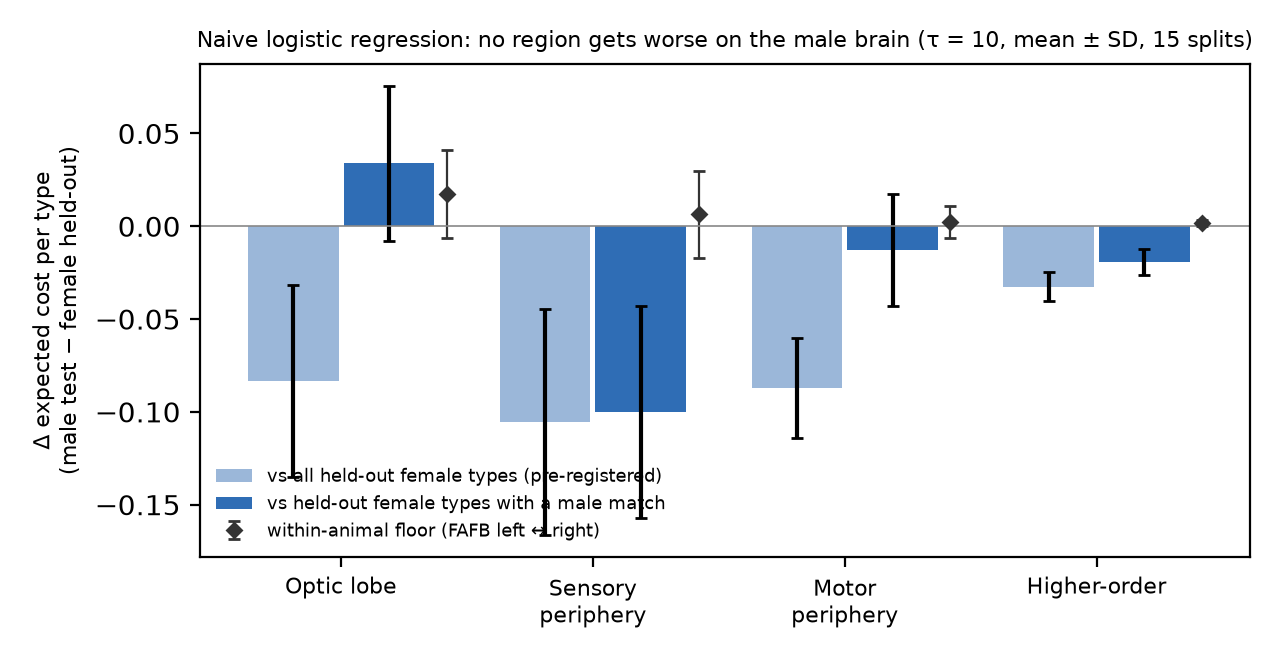

fig2_models_cost.png


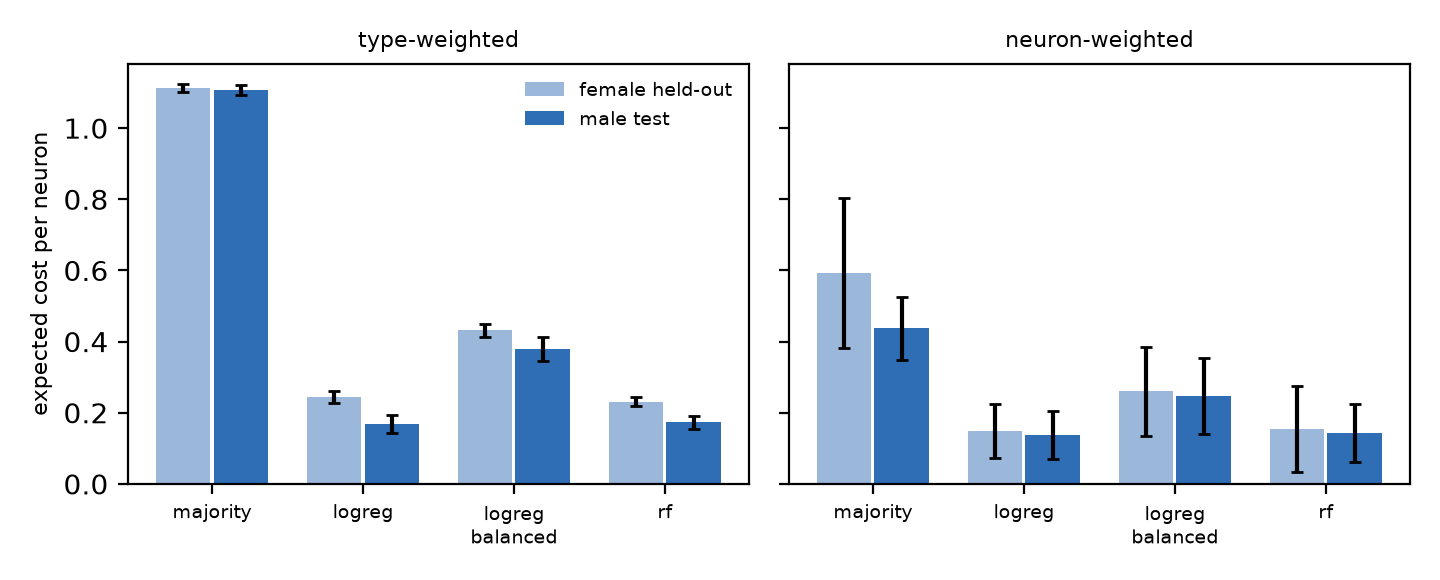

fig3_decision_rule.png


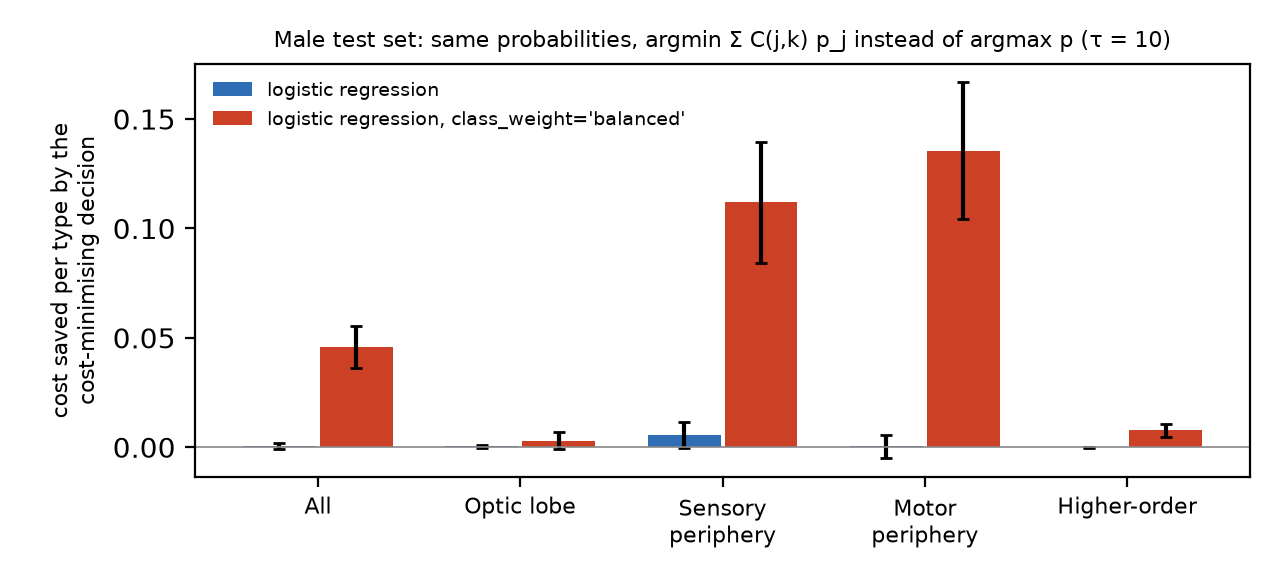

fig4_drop_by_dimorphism.png


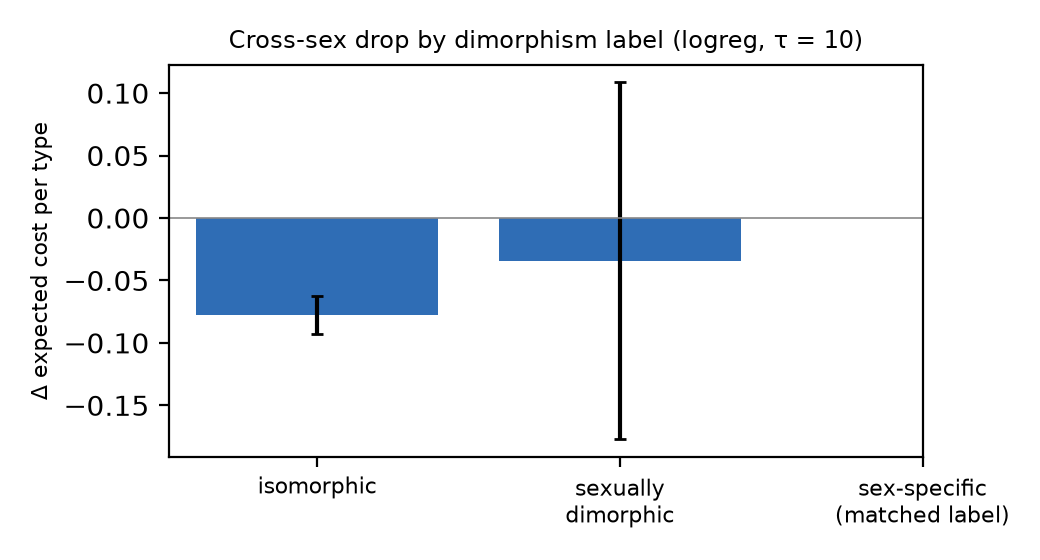

fig5_class_mix.png


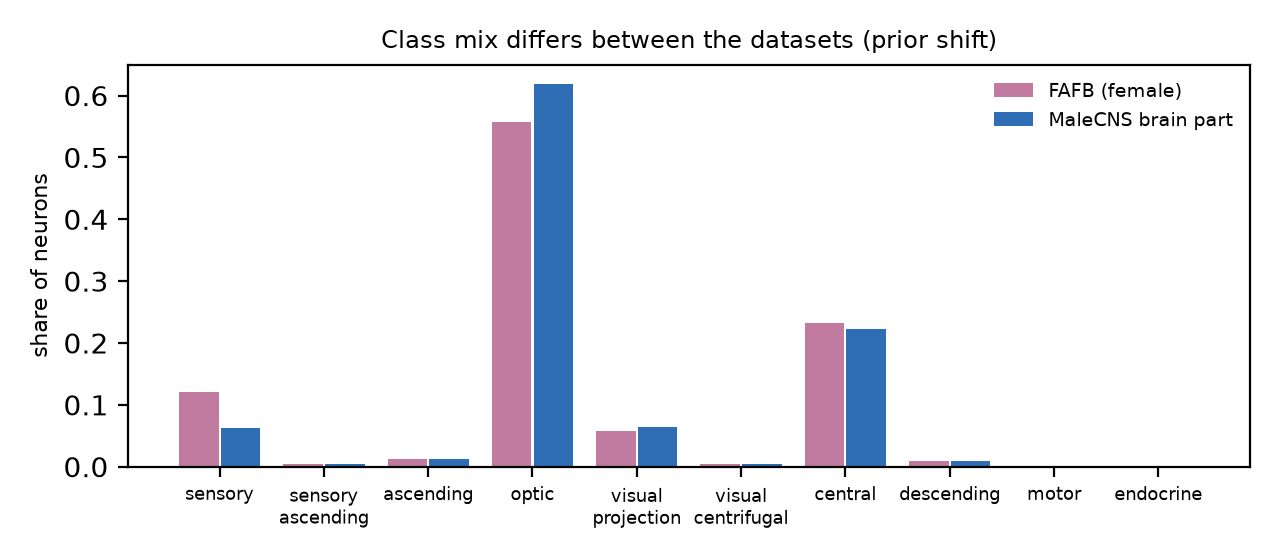

In [5]:
for p in sorted(Path("figures/week9").glob("*.png")):
    print(p.name); display(Image(filename=str(p), width=720))